# GeForce NOW Network Traffic Classification Using Machine Learning

**Project Type:** Machine Learning / Network Traffic Classification

## 1. Introduction
GeForce NOW is a cloud gaming service. Network communication between a user's device and a server contains packets that use different network protocols.

In this project, we analyse network packet data and build machine learning models to predict the **Protocol** of a packet using its packet length and time information.

## 2. Project Objectives
- Explore and understand the network traffic dataset.
- Clean the data and handle missing values.
- Visualize protocol counts and packet lengths.
- Extract useful features from packet timestamps.
- Train and compare four machine learning models.
- Predict the protocol of a new network packet.

## 3. Project Workflow
1. Import libraries and load the dataset.
2. Explore and clean the data.
3. Perform exploratory data analysis (EDA).
4. Extract features and encode the target.
5. Split the data into training and testing sets.
6. Train machine learning models.
7. Evaluate and compare model performance.
8. Predict the protocol of a new packet.

---
**Important:** Upload `GeForce_Now_merged.csv` when prompted, or change the file path in the data-loading cell if the CSV is stored elsewhere.

## 4. Import Required Libraries
We use Pandas and NumPy for data handling, Matplotlib and Seaborn for visualization, and Scikit-learn for machine learning.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

sns.set_theme(style="whitegrid")

## 5. Load the Dataset
Run this cell and select the `GeForce_Now_merged.csv` file from your computer.

In [6]:
import pandas as pd

# Directly load the existing dataset from the Colab workspace
file_name = '/content/GeForce_Now_merged.csv'
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,09-27 13:27:30.959547,10.215.173.1,112.217.128.200,UDP,106,49006 > 18747 Len=78,GeForce_Now_1.csv
573729,2022-09-27 13:27:30.966882,112.217.128.200,10.215.173.1,UDP,1332.0,19148 > 49005 Len=1304,GeForce_Now_1.csv
573730,2022-09-27 13:27:30.967038,112.217.128.200,10.215.173.1,UDP,1332.0,19148 > 49005 Len=1304,GeForce_Now_1.csv
573731,2022-09-27 13:27:30.967109,112.217.128.200,10.215.173.1,UDP,1332.0,19148 > 49005 Len=1304,GeForce_Now_1.csv
573732,2022-09-27 13:27:30.967200,112.217.128.200,10.215.173.1,UDP,1332.0,19148 > 49005 Len=1304,GeForce_Now_1.csv
573733,2022-09-27 13:27:30.967284,112.217.128.200,10.215.173.1,UDP,1332.0,19148 > 49005 Len=1304,GeForce_Now_1.csv


## 6. Data Understanding (Initial Exploration)
These commands help us inspect the first and last rows, summary statistics, dimensions, column names, data types, missing values, and duplicate rows.

In [7]:
display(df.head(10))
display(df.tail(10))

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all"))

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

,09-27 13:27:30.959547,10.215.173.1,112.217.128.200,UDP,106,49006 > 18747 Len=78,GeForce_Now_1.csv
573729,2022-09-27 13:27:30.966882,112.217.128.200,10.215.173.1,UDP,1332.0,19148 > 49005 Len=1304,GeForce_Now_1.csv
573730,2022-09-27 13:27:30.967038,112.217.128.200,10.215.173.1,UDP,1332.0,19148 > 49005 Len=1304,GeForce_Now_1.csv
573731,2022-09-27 13:27:30.967109,112.217.128.200,10.215.173.1,UDP,1332.0,19148 > 49005 Len=1304,GeForce_Now_1.csv
573732,2022-09-27 13:27:30.967200,112.217.128.200,10.215.173.1,UDP,1332.0,19148 > 49005 Len=1304,GeForce_Now_1.csv
573733,2022-09-27 13:27:30.967284,112.217.128.200,10.215.173.1,UDP,1332.0,19148 > 49005 Len=1304,GeForce_Now_1.csv
573734,2022-09-27 13:27:30.967370,112.217.128.200,10.215.173.1,UDP,1332.0,19148 > 49005 Len=1304,GeForce_Now_1.csv
573735,2022-09-27 13:27:30.967454,112.217.128.200,10.215.173.1,UDP,1332.0,19148 > 49005 Len=1304,GeForce_Now_1.csv
573736,2022-09-27 13:27:30.967537,112.217.128.200,10.215.173.1,UDP,419.0,19148 > 49005 Len=391,GeForce_Now_1.csv
573737,2022-09-27 13:27:30.967618,112.217.128.200,10.215.173.1,UDP,1332.0,19148 > 49005 Len=1304,GeForce_Now_1.csv
573738,2022-09-27 13:27:30.967701,112.217.128.200,10.215.173.1,UDP,1332.0,19148 > 49005 Len=1304,GeForce_Now_1.csv


,09-27 13:27:30.959547,10.215.173.1,112.217.128.200,UDP,106,49006 > 18747 Len=78,GeForce_Now_1.csv
765057,2022-09-27 13:29:56.136316,10.215.173.1,112.217.128.200,UDP,858.0,49006 > 18747 Len=830,GeForce_Now_1.csv
765058,2022-09-27 13:29:56.140902,112.217.128.200,10.215.173.1,UDP,329.0,13064 > 49003 Len=301,GeForce_Now_1.csv
765059,2022-09-27 13:29:56.140954,112.217.128.200,10.215.173.1,UDP,329.0,13064 > 49003 Len=301,GeForce_Now_1.csv
765060,2022-09-27 13:29:56.140969,112.217.128.200,10.215.173.1,UDP,341.0,13064 > 49003 Len=313,GeForce_Now_1.csv
765061,2022-09-27 13:29:56.140981,112.217.128.200,10.215.173.1,UDP,341.0,13064 > 49003 Len=313,GeForce_Now_1.csv
765062,2022-09-27 13:29:56.146407,10.215.173.1,112.217.128.200,UDP,137.0,49004 > 19779 Len=109,GeForce_Now_1.csv
765063,2022-09-27 13:29:56.146468,10.215.173.1,112.217.128.200,UDP,137.0,49004 > 19779 Len=109,GeForce_Now_1.csv
765064,2022-09-27 13:29:56.147425,112.217.128.200,10.215.173.1,UDP,329.0,13064 > 49003 Len=301,GeForce_Now_1.csv
765065,2022-09-27 13:29:56.147485,112.217.128.200,10.215.173.1,UDP,329.0,13064 > 49003 Len=301,GeForce_Now_1.csv
765066,2022-09-27 13:29:56.147602,112.217.128.200,1,NaN,NaN,NaN,NaN


Dataset shape: (191338, 7)

Column names:
['09-27 13:27:30.959547', '10.215.173.1', '112.217.128.200', 'UDP', '106', '49006  >  18747 Len=78', 'GeForce_Now_1.csv']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
Index: 191338 entries, 573729 to 765066
Data columns (total 7 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   09-27 13:27:30.959547   191338 non-null  object 
 1   10.215.173.1            191338 non-null  object 
 2   112.217.128.200         191338 non-null  object 
 3   UDP                     191337 non-null  object 
 4   106                     191337 non-null  float64
 5   49006  >  18747 Len=78  191337 non-null  object 
 6   GeForce_Now_1.csv       191337 non-null  object 
dtypes: float64(1), object(6)
memory usage: 11.7+ MB

Statistical summary:


,09-27 13:27:30.959547,10.215.173.1,112.217.128.200,UDP,106,49006 > 18747 Len=78,GeForce_Now_1.csv
count,191338,191338,191338,191337,191337.000000,191337,191337
unique,191338,2,3,4,NaN,1443,1
top,2022-09-27 13:27:30.966882,112.217.128.200,10.215.173.1,UDP,NaN,19148 > 49005 Len=1304,GeForce_Now_1.csv
freq,1,169209,169208,191192,NaN,110180,191337
mean,NaN,NaN,NaN,NaN,899.515948,NaN,NaN
std,NaN,NaN,NaN,NaN,524.584415,NaN,NaN
min,NaN,NaN,NaN,NaN,36.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,329.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,1332.000000,NaN,NaN
75%,NaN,NaN,NaN,NaN,1332.000000,NaN,NaN



Missing values:
09-27 13:27:30.959547     0
10.215.173.1              0
112.217.128.200           0
UDP                       1
106                       1
49006  >  18747 Len=78    1
GeForce_Now_1.csv         1
dtype: int64

Duplicate rows: 0


## 7. Data Cleaning
The dataset is expected to contain seven columns. We rename them for easier use and replace missing values with 0, following the original project approach. If your CSV has a different column structure, check the column names before renaming.

In [8]:
expected_columns = ["Time", "Source", "Destination", "Protocol",
                    "Length", "Info", "File_Name"]

if len(df.columns) != len(expected_columns):
    raise ValueError(
        f"Expected {len(expected_columns)} columns, but found {len(df.columns)}. "
        "Please check the uploaded CSV file."
    )

df.columns = expected_columns
df = df.fillna(0)

print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nCleaned dataset:")
display(df.head())

Missing values after cleaning:
Time           0
Source         0
Destination    0
Protocol       0
Length         0
Info           0
File_Name      0
dtype: int64

Cleaned dataset:


,Time,Source,Destination,Protocol,Length,Info,File_Name
573729,2022-09-27 13:27:30.966882,112.217.128.200,10.215.173.1,UDP,1332.0,19148 > 49005 Len=1304,GeForce_Now_1.csv
573730,2022-09-27 13:27:30.967038,112.217.128.200,10.215.173.1,UDP,1332.0,19148 > 49005 Len=1304,GeForce_Now_1.csv
573731,2022-09-27 13:27:30.967109,112.217.128.200,10.215.173.1,UDP,1332.0,19148 > 49005 Len=1304,GeForce_Now_1.csv
573732,2022-09-27 13:27:30.967200,112.217.128.200,10.215.173.1,UDP,1332.0,19148 > 49005 Len=1304,GeForce_Now_1.csv
573733,2022-09-27 13:27:30.967284,112.217.128.200,10.215.173.1,UDP,1332.0,19148 > 49005 Len=1304,GeForce_Now_1.csv


## 8. Protocol Analysis
The `Protocol` column contains the network protocol labels. We inspect the unique protocols and count how many packets belong to each protocol.

In [9]:
print("Unique protocols:")
print(df["Protocol"].unique())

print("\nProtocol counts:")
print(df["Protocol"].value_counts())

Unique protocols:
['UDP' 'TLSv1.2' 'TCP' 'RTCP' 0]

Protocol counts:
Protocol
UDP        191192
TLSv1.2        72
TCP            72
RTCP            1
0               1
Name: count, dtype: int64


### 8.1 Protocol Distribution
This count plot shows the number of packets for each protocol.

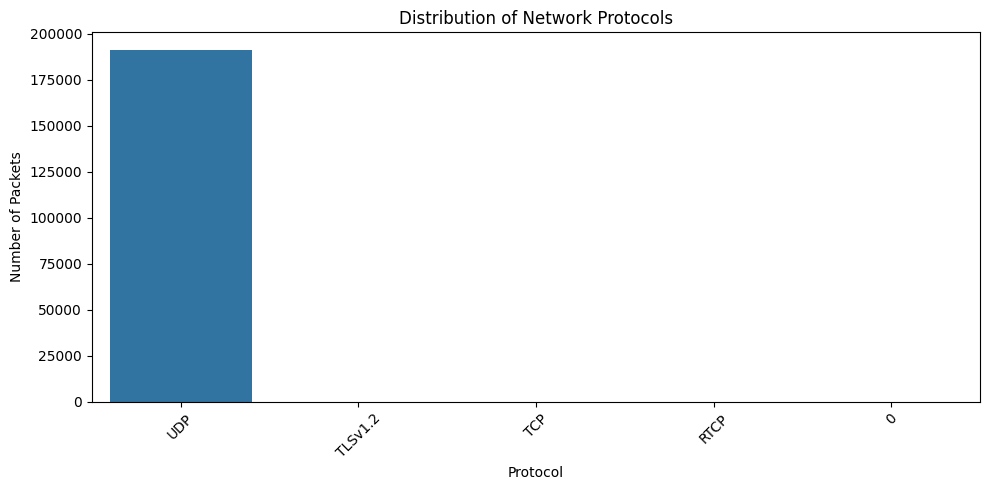

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x="Protocol",
    order=df["Protocol"].value_counts().index
)
plt.xticks(rotation=45)
plt.title("Distribution of Network Protocols")
plt.xlabel("Protocol")
plt.ylabel("Number of Packets")
plt.tight_layout()
plt.show()

## 9. Packet Length Analysis
We use descriptive statistics, a histogram, and a box plot to understand packet lengths and identify possible outliers.

count    191338.000000
mean        899.511247
std         524.587075
min           0.000000
25%         329.000000
50%        1332.000000
75%        1332.000000
max        1332.000000
Name: Length, dtype: float64


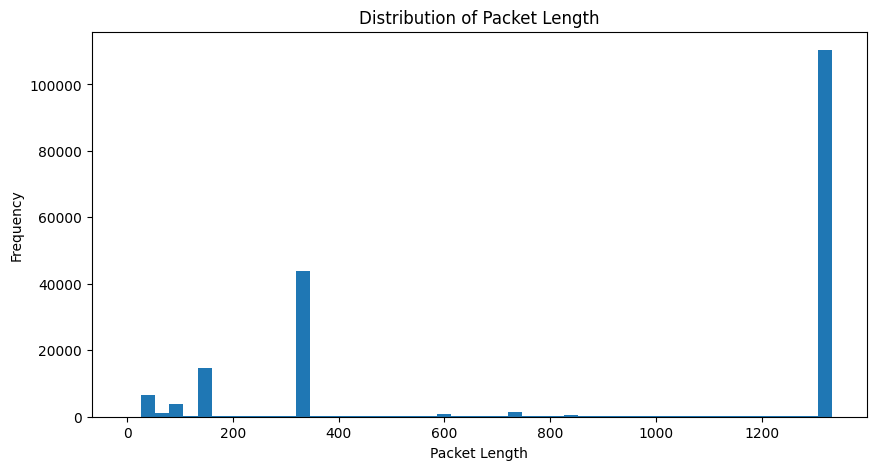

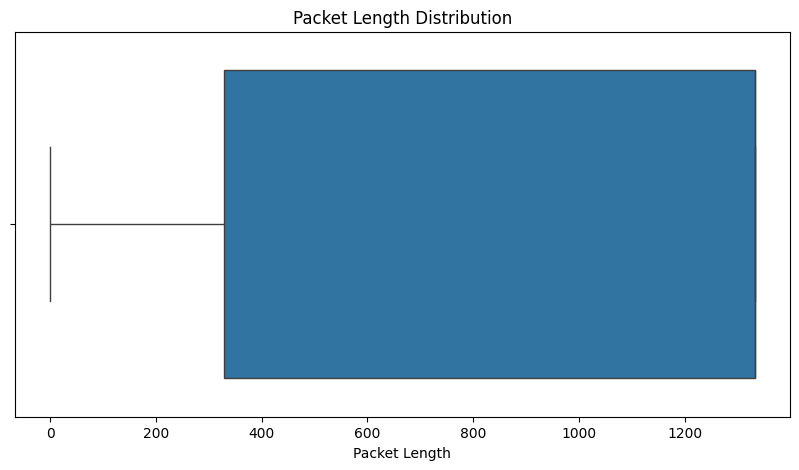

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df["Length"].describe())

plt.figure(figsize=(10, 5))
plt.hist(df["Length"], bins=50)
plt.title("Distribution of Packet Length")
plt.xlabel("Packet Length")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(x=df["Length"])
plt.title("Packet Length Distribution")
plt.xlabel("Packet Length")
plt.show()

## 10. Feature Extraction
The original `Time` column is converted into a datetime value. We extract `Hour`, `Minute`, and `Second`. These time components and `Length` are used as input features.

In [15]:
df["Time"] = pd.to_datetime(df["Time"], errors="coerce")

df["Hour"] = df["Time"].dt.hour
df["Minute"] = df["Time"].dt.minute
df["Second"] = df["Time"].dt.second

# Remove rows where required model features or the target are missing
df = df.dropna(subset=["Length", "Hour", "Minute", "Second", "Protocol"]).copy()

# Keep only numeric packet lengths
df["Length"] = pd.to_numeric(df["Length"], errors="coerce")
df = df.dropna(subset=["Length"]).copy()

display(df[["Time", "Length", "Hour", "Minute", "Second", "Protocol"]].head())

,Time,Length,Hour,Minute,Second,Protocol
573729,2022-09-27 13:27:30.966882,1332.0,13,27,30,UDP
573730,2022-09-27 13:27:30.967038,1332.0,13,27,30,UDP
573731,2022-09-27 13:27:30.967109,1332.0,13,27,30,UDP
573732,2022-09-27 13:27:30.967200,1332.0,13,27,30,UDP
573733,2022-09-27 13:27:30.967284,1332.0,13,27,30,UDP


## 11. Define Features and Target
**Features (X):** Length, Hour, Minute, and Second.  
**Target (y):** Protocol, which is the class that the model will predict.

In [16]:
feature_columns = ["Length", "Hour", "Minute", "Second"]
X = df[feature_columns]
y = df["Protocol"].astype(str)

print("Features:")
display(X.head())

print("Target:")
display(y.head())

print("X shape:", X.shape)
print("y shape:", y.shape)

Features:


,Length,Hour,Minute,Second
573729,1332.0,13,27,30
573730,1332.0,13,27,30
573731,1332.0,13,27,30
573732,1332.0,13,27,30
573733,1332.0,13,27,30


Target:


,Protocol
573729,UDP
573730,UDP
573731,UDP
573732,UDP
573733,UDP


X shape: (191338, 4)
y shape: (191338,)


## 12. Remove Rare Protocol Classes and Encode Labels
Stratified splitting requires at least two examples in each class. Therefore, protocol classes with fewer than two rows are removed. Label Encoding converts protocol names into numeric labels for model training.

In [19]:
from sklearn.preprocessing import LabelEncoder

protocol_counts = y.value_counts()
rare_protocols = protocol_counts[protocol_counts < 2].index.tolist()

print("Protocols removed because they have fewer than 2 records:", rare_protocols)

valid_rows = ~y.isin(rare_protocols)
X_filtered = X.loc[valid_rows].copy()
y_filtered = y.loc[valid_rows].copy()

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_filtered)

print("Remaining protocol classes:")
print(label_encoder.classes_)

Protocols removed because they have fewer than 2 records: ['RTCP', '0']
Remaining protocol classes:
['TCP' 'TLSv1.2' 'UDP']


## 13. Train-Test Split
We split the data into 80% training data and 20% testing data. `stratify` helps maintain the class distribution in both sets.

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_filtered,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (153068, 4)
Testing set shape: (38268, 4)


## 14. Feature Scaling
StandardScaler standardizes the numerical features. Logistic Regression and KNN are trained with scaling because these models can be affected by differences in feature ranges. A Pipeline ensures the scaler is fitted only on training data, avoiding data leakage.

In [27]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")
print("First five scaled training rows:")
print(X_train_scaled[:5])

Feature scaling completed.
First five scaled training rows:
[[ 0.82370596  0.          1.0930838  -0.49708413]
 [ 0.82370596  0.         -0.21047865  0.70775173]
 [ 0.82370596  0.         -0.21047865  1.49089503]
 [ 0.82370596  0.          1.0930838   1.24992786]
 [-0.8760286   0.          1.0930838   0.52702635]]


## 15. Model 1 — Logistic Regression
Logistic Regression is a classification algorithm that estimates the probability of each class and predicts the most likely class.

In [30]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print(f"Logistic Regression Accuracy: {accuracy_lr * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_lr,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

Logistic Regression Accuracy: 99.92%

Classification Report:
              precision    recall  f1-score   support

         TCP       0.00      0.00      0.00        15
     TLSv1.2       0.00      0.00      0.00        14
         UDP       1.00      1.00      1.00     38239

    accuracy                           1.00     38268
   macro avg       0.33      0.33      0.33     38268
weighted avg       1.00      1.00      1.00     38268



## 16. Model 2 — K-Nearest Neighbors (KNN)
KNN predicts a class by looking at the nearest training examples. Here, we use 5 neighbors.

In [32]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)
accuracy_knn = accuracy_score(y_test, y_pred_knn)

print(f"KNN Accuracy: {accuracy_knn * 100:.2f}%")

KNN Accuracy: 99.92%


## 17. Model 3 — Decision Tree
A Decision Tree makes predictions by splitting data according to feature-based rules. We limit its maximum depth to 10.

In [33]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42, max_depth=10)
dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print(f"Decision Tree Accuracy: {accuracy_dt * 100:.2f}%")

Decision Tree Accuracy: 99.99%


### 17.1 Decision Tree Visualization
The plot displays the first few levels of the trained decision tree.

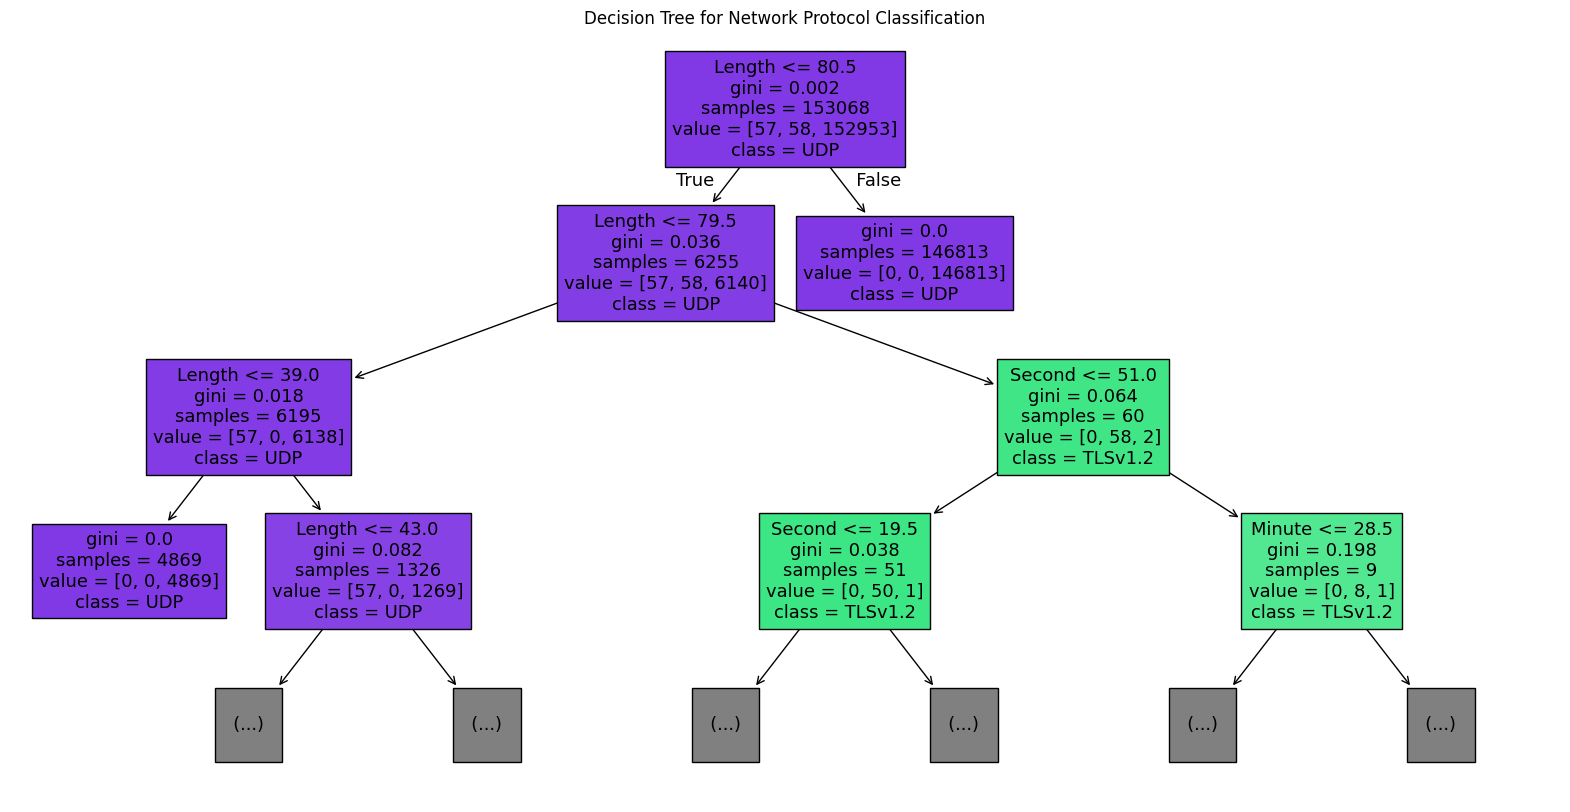

In [35]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))
plot_tree(
    dt_model,
    feature_names=feature_columns,
    class_names=label_encoder.classes_,
    filled=True,
    max_depth=3
)
plt.title("Decision Tree for Network Protocol Classification")
plt.show()

## 18. Model 4 — Random Forest
Random Forest combines predictions from multiple decision trees. In this project, we train 100 trees.

In [37]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print(f"Random Forest Accuracy: {accuracy_rf * 100:.2f}%")

Random Forest Accuracy: 99.99%


## 19. Compare Model Performance
We compare the accuracy of all four models using a results table and a bar chart. Accuracy is the proportion of correct predictions among all test predictions.

,Model,Accuracy,Accuracy (%)
0,Decision Tree,0.999922,99.992161
1,Random Forest,0.999869,99.986934
2,KNN,0.999242,99.924219
3,Logistic Regression,0.999242,99.924219


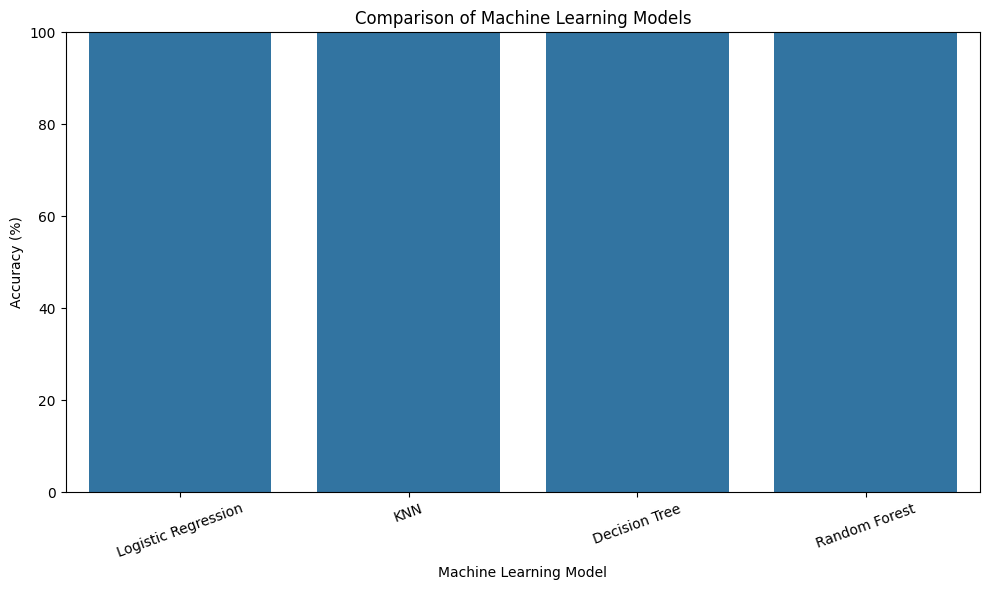

Best model based on accuracy:
Model           Decision Tree
Accuracy             0.999922
Accuracy (%)        99.992161
Name: 2, dtype: object


In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

results = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN", "Decision Tree", "Random Forest"],
    "Accuracy": [accuracy_lr, accuracy_knn, accuracy_dt, accuracy_rf]
})

results["Accuracy (%)"] = results["Accuracy"] * 100
display(results.sort_values("Accuracy", ascending=False).reset_index(drop=True))

plt.figure(figsize=(10, 6))
sns.barplot(data=results, x="Model", y="Accuracy (%)")
plt.xticks(rotation=20)
plt.ylim(0, 100)
plt.title("Comparison of Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.xlabel("Machine Learning Model")
plt.tight_layout()
plt.show()

best_model = results.loc[results["Accuracy"].idxmax()]
print("Best model based on accuracy:")
print(best_model)

## 20. Feature Importance — Random Forest
Feature importance indicates how useful each feature was for the Random Forest model's decision-making. Higher values indicate greater relative importance in this model.

,Feature,Importance
0,Length,0.973052
3,Second,0.023735
2,Minute,0.003213
1,Hour,0.000000


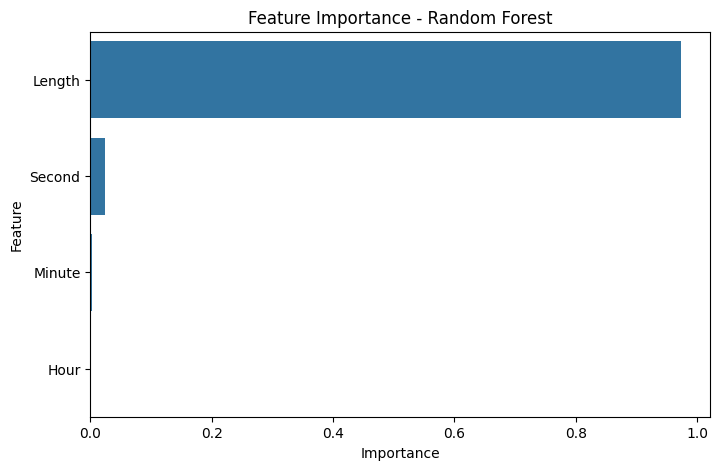

In [40]:
feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

display(feature_importance)

plt.figure(figsize=(8, 5))
sns.barplot(data=feature_importance, x="Importance", y="Feature")
plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

## 21. Random Forest Evaluation
The classification report shows precision, recall, and F1-score for each protocol. The confusion matrix compares actual protocol labels with predicted labels.

Random Forest Classification Report:
              precision    recall  f1-score   support

         TCP       1.00      1.00      1.00        15
     TLSv1.2       0.85      0.79      0.81        14
         UDP       1.00      1.00      1.00     38239

    accuracy                           1.00     38268
   macro avg       0.95      0.93      0.94     38268
weighted avg       1.00      1.00      1.00     38268



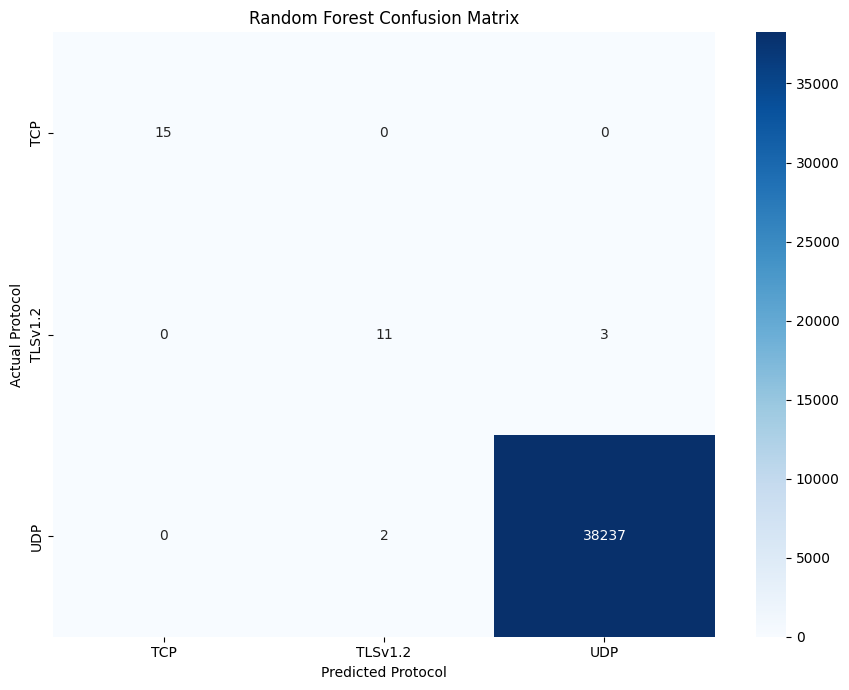

In [41]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

print("Random Forest Classification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

## 22. Predict the Protocol of a New Packet
We create one example packet with a length of 64 bytes and a timestamp of 10:30:15. The Random Forest model predicts its protocol. Since Random Forest was trained on unscaled features, we pass the new packet without scaling.

In [42]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

new_packet = pd.DataFrame({
    "Length": [64],
    "Hour": [10],
    "Minute": [30],
    "Second": [15]
})

prediction = rf_model.predict(new_packet)
predicted_protocol = label_encoder.inverse_transform(prediction)

print("New packet details:")
display(new_packet)
print("Predicted Protocol:", predicted_protocol[0])

New packet details:


,Length,Hour,Minute,Second
0,64,10,30,15


Predicted Protocol: UDP


## 23. Conclusion
In this project, we explored GeForce NOW network packet data and performed data cleaning, exploratory data analysis, feature extraction, and machine learning classification.

We trained and compared four classification algorithms: Logistic Regression, KNN, Decision Tree, and Random Forest. The model comparison table identifies which model achieved the highest accuracy on the test set.

The project also uses feature importance and a confusion matrix to understand model performance, and demonstrates how a trained model can predict the protocol of a new packet.

